# FIG 4 — Internal separability

This notebook reproduces FIG 4 from the source analysis. It compares univariate Gleason Grade Group separability across all ground-truth lesions, ground-truth lesions matched to detected cases, and detected surrogate lesions for Torino and Novara. See [README_FIG4.md](README_FIG4.md) for the full method, inputs, interpretation, and limitations.


In [ ]:
from pathlib import Path
import pandas as pd
def import_gt_dataset():
    
    df_psa_all = pd.read_csv('feature_tables/psa_density_all.csv')

    folders = ['T2_ring_iqr_zscore_stats2D_apply2D__ADC_ring_iqr_zscore_stats2D_apply2D_BIN_16',
    'T2_whole_prostate_iqr_zscore_stats2D_apply2D__ADC_whole_prostate_iqr_zscore_stats2D_apply2D_BIN_16',
    'T2_prostate_minus_lesion_iqr_zscore_stats2D_apply2D__ADC_prostate_minus_lesion_iqr_zscore_stats2D_apply2D_BIN_16',
    'T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16',
    'T2_none_iqr_zscore_stats2D_apply2D__ADC_none_iqr_zscore_stats2D_apply2D_BIN_16']


    folder = folders[3]

    base = Path(f"feature_tables_FINAL_2D/{folder}")

    images_path = next(base.glob("images_clean_*.csv"))
    radiomics_path = next(base.glob("radiomics_clean_*.csv"))
    labels_path = next(base.glob("labels_clean_*.csv"))

    images_all_gt = pd.read_csv(images_path)
    df_results_all_gt = pd.read_csv(radiomics_path)
    labels_all_gt = pd.read_csv(labels_path)
    #labels_all_gt = pd.read_csv('labels_scanner_uptodate.csv')

    print(images_path.name)
    print(radiomics_path.name)
    print(labels_path.name)

    df_results_all_gt = df_results_all_gt.transpose()[14:].transpose()#.drop(columns = ['T2_voxels','ADC_voxels'])
    df_psa_all = pd.read_csv('feature_tables/psa_density_all.csv')
    labels_all_gt['psa_density'] = df_psa_all['psa_density']
    labels_all_gt['scanner'] = pd.read_csv('labels_scanner_uptodate.csv')['scanner']

    df_results_all_gt['psa_density'] = df_psa_all['psa_density']
    #### here I'm just adding labels related to scanners

    IDX_US = 876
    IDX_PICAI = 425
    IDX_NOV = 77

    images_us = images_all_gt[:IDX_US].reset_index(drop = True)
    df_results_us = df_results_all_gt.iloc[:IDX_US].reset_index(drop = True)
    labels_us = labels_all_gt.iloc[:IDX_US].reset_index(drop = True)

    images_nov = images_all_gt[IDX_US + IDX_PICAI:IDX_US + IDX_PICAI + IDX_NOV].reset_index(drop=True)
    df_results_nov = df_results_all_gt.iloc[IDX_US + IDX_PICAI:IDX_US + IDX_PICAI + IDX_NOV].reset_index(drop=True)
    labels_nov = labels_all_gt.iloc[IDX_US + IDX_PICAI:IDX_US + IDX_PICAI + IDX_NOV].reset_index(drop=True)

    images_tor = images_all_gt[IDX_US + IDX_PICAI + IDX_NOV: ].reset_index(drop=True)
    df_results_tor = df_results_all_gt.iloc[IDX_US + IDX_PICAI + IDX_NOV:  ].reset_index(drop=True)
    labels_tor = labels_all_gt.iloc[IDX_US + IDX_PICAI + IDX_NOV: ].reset_index(drop=True)

    images_prostatex = images_all_gt[IDX_US :IDX_US + IDX_PICAI].reset_index(drop=True)
    df_results_prostatex = df_results_all_gt.iloc[IDX_US :IDX_US + IDX_PICAI].reset_index(drop=True)
    labels_prostatex = labels_all_gt.iloc[IDX_US :IDX_US + IDX_PICAI].reset_index(drop=True)

    labels_us['center'] = 'US-MRI'
    labels_nov['center'] = 'NOVARA'
    labels_tor['center'] = 'TORINO'
    labels_prostatex['center'] = 'PI-CAI'
    labels_all_gt = pd.concat([labels_us, labels_prostatex, labels_nov, labels_tor], ignore_index=True)#.drop(columns = 'Unnamed: 0')
    labels_all_gt['case_id'] = images_all_gt['case_id']

    # es: "SIEMENS-Skyra-3.0" -> tesla = 3.0
    labels_all_gt["tesla"] = labels_all_gt["scanner"].str.extract(r'-(\d+(?:\.\d+)?)$')[0].astype(float)
    images_all_gt['tesla'] = labels_all_gt['tesla']
    images_all_gt['scanner'] = labels_all_gt['scanner']
    images_all_gt['center'] = labels_all_gt['center']

    ## keep only numeric feature

    valid_columns = pd.read_csv('feature_tables/valid_columns.csv')['0'].tolist()
    df_results_all_gt = df_results_all_gt[valid_columns + ['psa_density']]
    labels_all_gt['scanner_c'] = labels_all_gt['scanner']+'_'+labels_all_gt['center']
    df_results_all_gt = df_results_all_gt.astype(float)
    return images_all_gt, df_results_all_gt, labels_all_gt

def import_pred_dataset():
    images_all_gt, df_results_all_gt, labels_all_gt = import_gt_dataset()

    path_label_gt = (
        pd.concat([labels_all_gt, images_all_gt], axis=1)
        .drop(columns='Unnamed: 0', errors='ignore')
        .loc[:, lambda x: ~x.columns.duplicated()]
    )

    images_val_pred = pd.read_csv('../for_uunet/images_preds_NEW.csv')
    feat_val_pred = pd.read_csv('../for_uunet/df_features_preds_NEW.csv')
    print(f"Predizioni val: images {images_val_pred.shape}, features {feat_val_pred.shape}")

    images_val_pred.loc[images_val_pred['idx'] < 77, 'center'] = 'Novara'

    images_train_pred = pd.read_csv('../for_uunet/images_preds_TRAIN_NEW.csv')
    feat_train_pred = pd.read_csv('../for_uunet/df_features_preds_TRAIN_NEW.csv')
    print(f"Predizioni train: images {images_train_pred.shape}, features {feat_train_pred.shape}")

    images_train_pred = images_train_pred.drop(columns='center', errors='ignore')

    # evita colonne duplicate già all'inizio
    images_val_pred = images_val_pred.loc[:, ~images_val_pred.columns.duplicated()]
    images_train_pred = images_train_pred.loc[:, ~images_train_pred.columns.duplicated()]
    feat_val_pred = feat_val_pred.loc[:, ~feat_val_pred.columns.duplicated()]
    feat_train_pred = feat_train_pred.loc[:, ~feat_train_pred.columns.duplicated()]

    # metadata GT da attaccare alle predizioni
    gt_meta_cols = ['center', 'scanner', 'psa_density', 'nii_segms', 'tesla']

    gt_meta = (
        path_label_gt[gt_meta_cols]
        .rename(columns={'nii_segms': 'gt_path'})
        .drop_duplicates(subset=['gt_path'])
        .loc[:, lambda x: ~x.columns.duplicated()]
    )

    images_train_pred = images_train_pred.merge(
        gt_meta,
        on='gt_path',
        how='left'
    )

    images_val_pred = images_val_pred.merge(
        gt_meta,
        on='gt_path',
        how='left',
        suffixes=('', '_gt')
    )

    # se dopo il merge rimangono colonne *_gt, usa quelle solo se servono
    for col in ['center', 'scanner', 'psa_density', 'tesla']:
        gt_col = f'{col}_gt'
        if gt_col in images_val_pred.columns:
            images_val_pred[col] = images_val_pred[col].fillna(images_val_pred[gt_col])
            images_val_pred = images_val_pred.drop(columns=gt_col)

    # togli duplicati dopo merge
    images_val_pred = images_val_pred.loc[:, ~images_val_pred.columns.duplicated()]
    images_train_pred = images_train_pred.loc[:, ~images_train_pred.columns.duplicated()]

    # aggiungi psa_density alle features
    feat_val_pred['psa_density'] = images_val_pred['psa_density'].values
    feat_train_pred['psa_density'] = images_train_pred['psa_density'].values

    # allinea colonne features con GT
    common_cols = sorted(set(df_results_all_gt.columns).intersection(feat_train_pred.columns))

    df_results_all = df_results_all_gt[common_cols]
    feat_train_pred = feat_train_pred[common_cols]
    feat_val_pred = feat_val_pred[common_cols]

    # split
    images_val_pred['split'] = 'external'
    images_train_pred['split'] = 'train'

    # rinomina path in formato compatibile con GT
    rename_map = {
        'adc_path': 'nii_images_ADC',
        't2_path': 'nii_images',
        'mask_path': 'nii_segms'
    }

    images_val_pred = images_val_pred.rename(columns=rename_map)
    images_train_pred = images_train_pred.rename(columns=rename_map)

    # colonne labels coerenti con labels_all_gt
    label_base_cols = (
        labels_all_gt
        .drop(columns=['Subject', 'scanner_c'], errors='ignore')
        .columns
        .tolist()
    )

    extra_cols = [
        'dice',
        'is_tp',
        'is_fp',
        'dice_vs_gt_global',
        'overlap_nonzero'
    ]

    label_cols = label_base_cols + extra_cols

    # tieni solo colonne che esistono davvero
    label_cols_val = [c for c in label_cols if c in images_val_pred.columns]
    label_cols_train = [c for c in label_cols if c in images_train_pred.columns]

    labels_val_pred = images_val_pred[label_cols_val].copy()
    labels_train_pred = images_train_pred[label_cols_train].copy()

    labels_val_pred = labels_val_pred.loc[:, ~labels_val_pred.columns.duplicated()]
    labels_train_pred = labels_train_pred.loc[:, ~labels_train_pred.columns.duplicated()]

    images_all_PRED = pd.concat([images_train_pred, images_val_pred], axis=0, ignore_index=True)
    labels_all_PRED = pd.concat([labels_train_pred, labels_val_pred], axis=0, ignore_index=True)
    df_results_all_PRED = pd.concat([feat_train_pred, feat_val_pred], axis=0, ignore_index=True)

    return images_all_PRED, df_results_all_PRED, labels_all_PRED

## Load ground-truth and detected-lesion datasets

The loaders below use the original feature-table selection and prediction inputs. The original FIG 4 code matches GT lesions against all surrogate prediction case IDs, then separately restricts the detected-lesion cohort to rows with `dice > 0`.


In [ ]:
# Load the GT feature matrix and labels.
_, df_results_all_gt, labels_all_gt = import_gt_dataset()

# The prediction loader also builds the surrogate feature matrix and labels.
_, df_results_all_surr, labels_all_surr = import_pred_dataset()


## Compute separability and render the figure

For each feature and center, the plotting cell computes `AUC_f = |AUC - 0.5|` for the binary target `GG <= 2` versus `GG >= 3`. The figure code and its previously saved output are retained from the `FIG 4` section of the source notebook.


Dataset sizes:
All GT lesions        : X=(1462, 201), labels=(1462, 8)
Matched GT lesions    : X=(897, 201), labels=(897, 9)
Detected lesions      : X=(917, 201), labels=(917, 11)


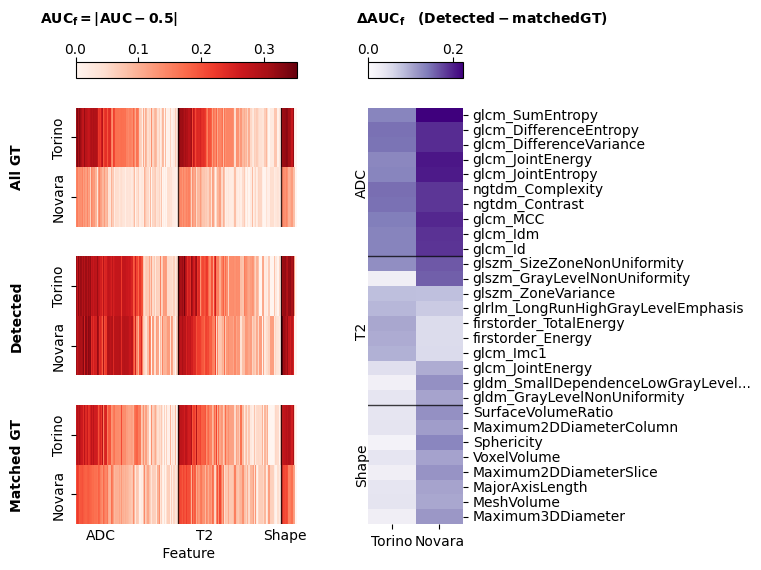

In [128]:
import os
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# =========================================================
# CONFIG
# =========================================================
CENTER_ORDER = ["TORINO", "NOVARA"]
MIN_CLASS_PER_CENTER = 5

TOP_ADC_DELTA = 10
TOP_T2_DELTA = 10
TOP_SHAPE_DELTA = 8

FS_TITLE = 10
FS_LABEL = 10
FS_TICK = 10
FS_FEATURE = 10
FS_GROUP = 10
FS_ROW = 10

LEFT_CMAP = "Reds"
RIGHT_CMAP = "Purples"

SAVE_FIG = True
OUT_PATH = "report_final/feature_separability_gt_matched_detected_delta.pdf"

# =========================================================
# HELPERS
# =========================================================
def normalize_centers(labels):
    labels = labels.copy()
    labels["center"] = labels["center"].replace({
        "Torino": "TORINO",
        "Novara": "NOVARA",
        "torino": "TORINO",
        "novara": "NOVARA",
    })
    return labels


def get_modality(feature):
    feature = str(feature)

    if "shape" in feature.lower():
        return "Shape"
    if feature.startswith("ADC_"):
        return "ADC"
    if feature.startswith("T2_"):
        return "T2"

    return "Other"


def clean_feature_name(feature, maxlen=35):

    s = str(feature)

    s = re.sub(r"^ADC_", "", s)
    s = re.sub(r"^T2_", "", s)

    s = re.sub(r"^ADC_shape_", "", s)
    s = re.sub(r"^T2_shape_", "", s)
    s = re.sub(r"^shape_", "", s)

    if len(s) > maxlen:
        s = s[:maxlen - 3] + "..."

    return s


def compute_auc_signal_table(df_features, labels, center_order=CENTER_ORDER):
    labels = normalize_centers(labels)

    common_idx = df_features.index.intersection(labels.index)
    X = df_features.loc[common_idx].copy()
    y = labels.loc[common_idx].copy()

    mask = y["center"].isin(center_order) & (y["GG"] > -1)
    X = X.loc[mask].copy()
    y = y.loc[mask].copy()

    y_bin = (y["GG"] >= 3).astype(int)

    rows = []

    for center in center_order:
        mask_c = y["center"] == center
        Xc = X.loc[mask_c].copy()
        yc = y_bin.loc[mask_c].copy()

        for feature in Xc.columns:
            x = Xc[feature]
            valid = x.notna() & yc.notna()

            n0 = int(((yc == 0) & valid).sum())
            n1 = int(((yc == 1) & valid).sum())

            if n0 < MIN_CLASS_PER_CENTER or n1 < MIN_CLASS_PER_CENTER:
                auc = np.nan
                auc_signal = np.nan
            else:
                try:
                    auc = roc_auc_score(yc[valid], x[valid])
                    auc_signal = abs(auc - 0.5)
                except Exception:
                    auc = np.nan
                    auc_signal = np.nan

            rows.append({
                "center": center,
                "feature": feature,
                "n_GG_le2": n0,
                "n_GG_ge3": n1,
                "auc": auc,
                "auc_signal": auc_signal,
                "modality": get_modality(feature),
            })

    long_df = pd.DataFrame(rows)

    table = (
        long_df
        .pivot(index="feature", columns="center", values="auc_signal")
        .reindex(columns=center_order)
    )

    return table, long_df


def align_gt_to_detected_cases(df_gt, labels_gt, labels_surr):
    labels_gt = normalize_centers(labels_gt)
    labels_surr = normalize_centers(labels_surr)

    detected_case_ids = labels_surr["case_id"].dropna().unique()
    labels_gt_reset = labels_gt.reset_index(drop=False)

    labels_gt_matched = (
        labels_gt_reset
        .set_index("case_id")
        .loc[detected_case_ids]
        .reset_index()
    )

    if "Subject" in labels_gt_matched.columns:
        feature_index = labels_gt_matched["Subject"].values
    elif "index" in labels_gt_matched.columns:
        feature_index = labels_gt_matched["index"].values
    else:
        raise ValueError(
            "Cannot infer feature index for matched GT lesions. "
            "Expected 'Subject' or original index column."
        )

    df_gt_matched = df_gt.loc[feature_index].copy()

    labels_gt_matched.index = np.arange(len(labels_gt_matched))
    df_gt_matched.index = labels_gt_matched.index

    return df_gt_matched, labels_gt_matched


def add_feature_group_labels_top(
    ax,
    adc_features,
    t2_features,
    shape_features,
    y=-0.15
):
    groups = [
        ("ADC", len(adc_features)),
        ("T2", len(t2_features)),
        ("Shape", len(shape_features)),
    ]

    start = 0
    total = sum(n for _, n in groups)

    for label, n in groups:
        if n == 0:
            continue

        center = start + n / 4

        ax.text(
            center / total,
            y,
            label,
            transform=ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=FS_GROUP,
            #fontweight="bold",
        )

        start += n


def plot_grouped_signal_heatmap(
    ax,
    table,
    row_label,
    adc_features,
    t2_features,
    shape_features,
    global_vmax,
    show_group_labels=False,
    cmap=LEFT_CMAP,
):
    table_t = table.T

    sns.heatmap(
        table_t,
        ax=ax,
        cmap=cmap,
        vmin=0,
        vmax=global_vmax,
        cbar=False,
    )

    boundaries = [
        len(adc_features),
        len(adc_features) + len(t2_features),
        len(adc_features) + len(t2_features) + len(shape_features),
    ]

    for b in boundaries:
        if b > 0 and b < table.shape[0]:
            ax.axvline(
                b,
                color="black",
                linewidth=1.0,
                alpha=0.75,
            )

    ax.set_xticks([])
    ax.set_xlabel("")

    ax.set_ylabel(
        row_label,
        fontsize=FS_ROW,
        fontweight="bold",
        rotation=90,
        labelpad=20,
    )

    ax.tick_params(axis="y", labelsize=FS_TICK)

    if show_group_labels:
        add_feature_group_labels_top(
            ax=ax,
            adc_features=adc_features,
            t2_features=t2_features,
            shape_features=shape_features,
        )


def add_delta_group_labels_right(ax, groups, x=-0.14):

    total = sum(n for _, n in groups)
    start = 0

    for label, n in groups:

        if n == 0:
            continue

        center = start + n / 2

        ax.text(
            x,
            1 - center / total,
            label,
            transform=ax.transAxes,
            ha="left",
            va="center",
            fontsize=FS_GROUP,
            #fontweight="bold",
            rotation=90,
        )

        start += n


# =========================================================
# 1. PREPARE THREE DATASETS
# =========================================================
labels_gt_all = normalize_centers(labels_all_gt)
labels_surr_all = normalize_centers(labels_all_surr)

df_gt_all = df_results_all_gt.copy()
df_surr_all = df_results_all_surr.copy()

if not labels_gt_all.index.equals(df_gt_all.index):
    if "Subject" in labels_gt_all.columns and labels_gt_all["Subject"].isin(df_gt_all.index).all():
        labels_gt_all = labels_gt_all.set_index("Subject", drop=False)
    elif "case_id" in labels_gt_all.columns and labels_gt_all["case_id"].isin(df_gt_all.index).all():
        labels_gt_all = labels_gt_all.set_index("case_id", drop=False)

if not labels_surr_all.index.equals(df_surr_all.index):
    if "Subject" in labels_surr_all.columns and labels_surr_all["Subject"].isin(df_surr_all.index).all():
        labels_surr_all = labels_surr_all.set_index("Subject", drop=False)
    elif "case_id" in labels_surr_all.columns and labels_surr_all["case_id"].isin(df_surr_all.index).all():
        labels_surr_all = labels_surr_all.set_index("case_id", drop=False)

df_all_gt = df_gt_all.copy()
lab_all_gt = labels_gt_all.copy()

df_matched_gt, lab_matched_gt = align_gt_to_detected_cases(
    df_gt=df_gt_all,
    labels_gt=labels_gt_all,
    labels_surr=labels_surr_all,
)

df_detected = df_surr_all.copy()
lab_detected = labels_surr_all.copy()

if "dice" in lab_detected.columns:
    mask_detected = lab_detected["dice"] > 0
    df_detected = df_detected.loc[mask_detected].copy()
    lab_detected = lab_detected.loc[mask_detected].copy()

df_detected = df_detected.loc[lab_detected.index].copy()

datasets = {
    "All GT lesions": (df_all_gt, lab_all_gt),
    "Matched GT lesions": (df_matched_gt, lab_matched_gt),
    "Detected lesions": (df_detected, lab_detected),
}

print("Dataset sizes:")
for name, (df_, lab_) in datasets.items():
    print(f"{name:22s}: X={df_.shape}, labels={lab_.shape}")

# =========================================================
# 2. COMPUTE FEATURE-LEVEL SEPARABILITY TABLES
# =========================================================
tables = {}
long_tables = {}

for name, (df_, lab_) in datasets.items():
    tab, long_df = compute_auc_signal_table(df_, lab_)
    tables[name] = tab
    long_tables[name] = long_df

# =========================================================
# 3. COMMON FEATURE ORDER: ADC | T2 | Shape
# =========================================================
combined_signal = pd.concat(tables.values(), axis=1)

feature_order_all = (
    combined_signal
    .mean(axis=1, skipna=True)
    .sort_values(ascending=False)
    .index
)

adc_features = [f for f in feature_order_all if get_modality(f) == "ADC"]
t2_features = [f for f in feature_order_all if get_modality(f) == "T2"]
shape_features = [f for f in feature_order_all if get_modality(f) == "Shape"]

feature_order_grouped = (
    adc_features
    + t2_features
    + shape_features
)

tables = {
    name: tab.reindex(feature_order_grouped)
    for name, tab in tables.items()
}

# =========================================================
# 4. COMMON COLOR SCALE FOR LEFT PANELS
# =========================================================
global_vmax = max(
    np.nanmax(tab.to_numpy())
    for tab in tables.values()
)

# =========================================================
# 5. DELTA: Detected lesions - Matched GT lesions
# =========================================================
matched_gt_tab = tables["Matched GT lesions"]
detected_tab = tables["Detected lesions"]

delta_tab = detected_tab - matched_gt_tab

delta_summary = pd.DataFrame({
    "delta_mean": delta_tab.mean(axis=1, skipna=True),
    "delta_TORINO": delta_tab["TORINO"],
    "delta_NOVARA": delta_tab["NOVARA"],
    "matched_GT_mean": matched_gt_tab.mean(axis=1, skipna=True),
    "detected_mean": detected_tab.mean(axis=1, skipna=True),
})

delta_summary["modality"] = delta_summary.index.to_series().apply(get_modality)

delta_adc = (
    delta_summary[delta_summary["modality"] == "ADC"]
    .sort_values("delta_mean", ascending=False)
)
delta_t2 = (
    delta_summary[delta_summary["modality"] == "T2"]
    .sort_values("delta_mean", ascending=False)
)
delta_shape = (
    delta_summary[delta_summary["modality"] == "Shape"]
    .sort_values("delta_mean", ascending=False)
)

top_adc = delta_adc.head(TOP_ADC_DELTA).index.tolist()
top_t2 = delta_t2.head(TOP_T2_DELTA).index.tolist()
top_shape = delta_shape.head(TOP_SHAPE_DELTA).index.tolist()

top_delta_features = top_adc + top_t2 + top_shape

delta_plot = delta_tab.loc[top_delta_features, CENTER_ORDER].copy()

delta_vmax = np.nanmax(delta_plot.to_numpy())
if not np.isfinite(delta_vmax) or delta_vmax <= 0:
    delta_vmax = 1.0

delta_plot = delta_plot.copy()

delta_plot.columns = (
    delta_plot.columns
    .str.replace("TORINO", "Torino")
    .str.replace("NOVARA", "Novara")
)

delta_plot_display = delta_plot.copy()
delta_plot_display.index = [
    clean_feature_name(f)
    for f in delta_plot_display.index
]

# =========================================================
# 6. FIGURE
# =========================================================
fig = plt.figure(figsize=(5, 6))

gs = fig.add_gridspec(
    4,
    2,
    width_ratios=[0.7, 0.3],
    height_ratios=[0.13, 1, 1, 1],
    wspace=0.45,
    hspace=0.32,
)

cax_left = fig.add_subplot(gs[0, 0])
cax_right = fig.add_subplot(gs[0, 1])

ax_all_gt = fig.add_subplot(gs[1, 0])
ax_row2 = fig.add_subplot(gs[2, 0], sharex=ax_all_gt, sharey=ax_all_gt)
ax_row3 = fig.add_subplot(gs[3, 0], sharex=ax_all_gt, sharey=ax_all_gt)

ax_delta = fig.add_subplot(gs[1:, 1])

# ---------------------------------------------------------
# Colorbar left: AUC_f
# ---------------------------------------------------------
sm_left = ScalarMappable(
    norm=Normalize(vmin=0, vmax=global_vmax),
    cmap=LEFT_CMAP,
)
sm_left.set_array([])

cb_left = fig.colorbar(
    sm_left,
    cax=cax_left,
    orientation="horizontal",
)

cb_left.set_label(
    r"$\mathbf{AUC_f = |AUC - 0.5|}$" + '\n',
    fontsize=FS_LABEL,
   # fontweight="bold",
    labelpad=2,
)

cb_left.ax.xaxis.set_label_position("top")
cb_left.ax.xaxis.set_ticks_position("top")
cb_left.ax.tick_params(labelsize=FS_TICK, pad=1)

# ---------------------------------------------------------
# Colorbar right: Delta AUC_f
# ---------------------------------------------------------
sm_right = ScalarMappable(
    norm=Normalize(vmin=0, vmax=delta_vmax),
    cmap=RIGHT_CMAP,
)
sm_right.set_array([])

cb_right = fig.colorbar(
    sm_right,
    cax=cax_right,
    orientation="horizontal",
)

cb_right.set_label(
    r"$\mathbf{\Delta AUC_f \quad (Detected - matched GT)}$" + '\n' ,
    fontsize=FS_LABEL,
    labelpad=2,
   # fontweight="bold",
)
cb_right.ax.xaxis.set_label_coords(1.2, 2.4)
cb_left.ax.xaxis.set_label_coords(.15, 2.4)

cb_left.ax.xaxis.label.set_fontweight("bold")
cb_right.ax.xaxis.label.set_fontweight("bold")

cb_right.ax.xaxis.set_label_position("top")
cb_right.ax.xaxis.set_ticks_position("top")
cb_right.ax.tick_params(labelsize=FS_TICK, pad=1)

# ---------------------------------------------------------
# Left column
# ---------------------------------------------------------
left_panels = [
    ("All GT", tables["All GT lesions"], ax_all_gt),
    ("Detected", tables["Detected lesions"], ax_row2),
    ("Matched GT", tables["Matched GT lesions"], ax_row3),
]

for i, (row_label, tab, ax_i) in enumerate(left_panels):

    tab = tab.copy()

    tab.columns = (
        tab.columns
        .str.replace("TORINO", "Torino")
        .str.replace("NOVARA", "Novara")
    )

    plot_grouped_signal_heatmap(
        ax=ax_i,
        table=tab,
        row_label=row_label,
        adc_features=adc_features,
        t2_features=t2_features,
        shape_features=shape_features,
        global_vmax=global_vmax,
        show_group_labels=(i == 2),
        cmap=LEFT_CMAP,
    )

ax_row3.set_xlabel("\n Feature", fontsize=FS_LABEL)

# ---------------------------------------------------------
# Right column: delta panel
# ---------------------------------------------------------
hm = sns.heatmap(
    delta_plot_display,
    ax=ax_delta,
    cmap=RIGHT_CMAP,
    vmin=0,
    vmax=delta_vmax,
    cbar=False,
)

boundaries = [
    len(top_adc),
    len(top_adc) + len(top_t2),
]

for b in boundaries:
    if b > 0 and b < len(top_delta_features):
        ax_delta.axhline(
            b,
            color="black",
            linewidth=1.0,
            alpha=0.75,
        )

"""
ax_delta.set_title(
    "Detected - matched GT",
    fontsize=FS_TITLE,
    fontweight="bold",
    loc="left",
)
"""

ax_delta.set_xlabel("", fontsize=FS_LABEL)
ax_delta.set_ylabel("")
ax_delta.tick_params(axis="x", labelsize=FS_TICK)
ax_delta.tick_params(axis="y", labelsize=FS_FEATURE)

delta_groups = [
    ("ADC", len(top_adc)),
    ("T2", len(top_t2)),
    ("Shape", len(top_shape)),
]

add_delta_group_labels_right(
    ax_delta,
    delta_groups,
    x=-0.14,
)

ax_delta.yaxis.tick_right()
ax_delta.yaxis.set_label_position("right")

for lab in ax_delta.get_yticklabels():
    lab.set_rotation(0)
    lab.set_horizontalalignment("left")
    lab.set_verticalalignment("center")

plt.tight_layout()

if SAVE_FIG:
    os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
    plt.savefig(OUT_PATH, bbox_inches="tight")

plt.show()